Análise de variações no MCTS:

In [26]:
!python --version

Python 3.11.15


In [1]:
#imports
from game import Game
from players import MCTS

In [28]:
#o método run do Game é mais para poder jogar no terminal com prints e assim
#notebook_run feito de proprósito para a análise
stats = Game("","").notebook_run("mcts_simplest", MCTS().move, "mcts_heuristic_win", MCTS(heuristic_win=True).move)
print(stats)

{'player1': 'mcts_simplest', 'player2': 'mcts_heuristic_win', 'winner': -1, 'winner_name': 'mcts_heuristic_win', 'time_player1': 2.941315856005531, 'time_player2': 1.7322501290473156, 'avg_time_player1': 0.24510965466712756, 'avg_time_player2': 0.14435417742060963}


In [2]:
# "mcts_simplest":MCTS(child_limit=8,).move,
# "mcts_heuristic_win":MCTS(child_limit=8,heuristic_win=True).move, #selects win state during simulation
# "mcts_heuristic_block_win" : MCTS(child_limit=8,heuristic_block_win=True).move, #doesnt chose a move that lets the opponent win
# "mcts_win_and_block_win" : MCTS(child_limit=8,heuristic_win=True, heuristic_block_win=True).move,
# "mcts_tree":MCTS(child_limit=8,save_tree=True).move, #one of the above, but saving the tree
# "mcts_full" : MCTS(child_limit=8,heuristic_win=True, heuristic_block_win=True, save_tree=True).move,#block_win deixa muito lento
child_variants_300 = [
      ("all_300", MCTS(max_iter=300)),
      ("child_2_300", MCTS(child_limit=2, max_iter=300)),
      ("child_4_300", MCTS(child_limit=4, max_iter=300)),
      ("child_8_300", MCTS(child_limit=8, max_iter=300)),
]
# "mcts_select_8_children_more_iters" : MCTS(child_limit=8, max_iter=500).move,
# "mcts_select_all_children_more_iters" : MCTS(max_iter=500).move,

In [3]:
child_variants_300 = [
    ("all_300", MCTS(max_iter=300)),
    ("child_2_300", MCTS(child_limit=2, max_iter=300)),
    ("child_4_300", MCTS(child_limit=4, max_iter=300)),
    ("child_8_300", MCTS(child_limit=8, max_iter=300)),
]

In [4]:
#p1 vs p2 e p2 vs p1 se n_games=5 então corre-se 10 jogos no total entre eles
def variants_stats(variants, n_games=5):
    stats= {}
    for name, _ in variants:
        stats[name] = {
            "wins": 0,
            "draws": 0,
            "losses": 0,
            "avg_time_sum": 0 # sum of the avg times per move for all the games
        }

    for i in range(len(variants)):
        for j in range(i + 1, len(variants)):
            for (p1, mcts1), (p2, mcts2) in [(variants[i], variants[j]),(variants[j], variants[i])]:
                for _ in range(n_games):
                    #reset the root node of the tree
                    mcts1.root = None 
                    mcts2.root = None
                    res = Game("","").notebook_run(p1,mcts1.move,p2,mcts2.move)
                    
                    stats[p1]["avg_time_sum"] += res["avg_time_player1"]
                    stats[p2]["avg_time_sum"] += res["avg_time_player2"]

                    if res["winner"] == 1:
                        stats[p1]["wins"] += 1
                        stats[p2]["losses"] += 1
                    elif res["winner"] == -1:
                        stats[p2]["wins"] += 1
                        stats[p1]["losses"] += 1
                    else:
                        stats[p1]["draws"] += 1
                        stats[p2]["draws"] += 1

    total_games = n_games * 2 * (len(variants)-1) #cada mcts jogou com os outros todos 2 vezes
    for v in stats:
        total = stats[v]["wins"] + stats[v]["draws"] + stats[v]["losses"]

        stats[v]["win_rate"] = stats[v]["wins"] / total
        stats[v]["draw_rate"] = stats[v]["draws"] / total
        stats[v]["loss_rate"] = stats[v]["losses"] / total
        stats[v]["avg_time_per_move"] = stats[v]["avg_time_sum"] / total_games

    return stats


In [ ]:
stats_children = variants_stats(child_variants_300, n_games=10)
#mas assim perde-se a informação sobre contra quem exatamente eles perderam
#4mins

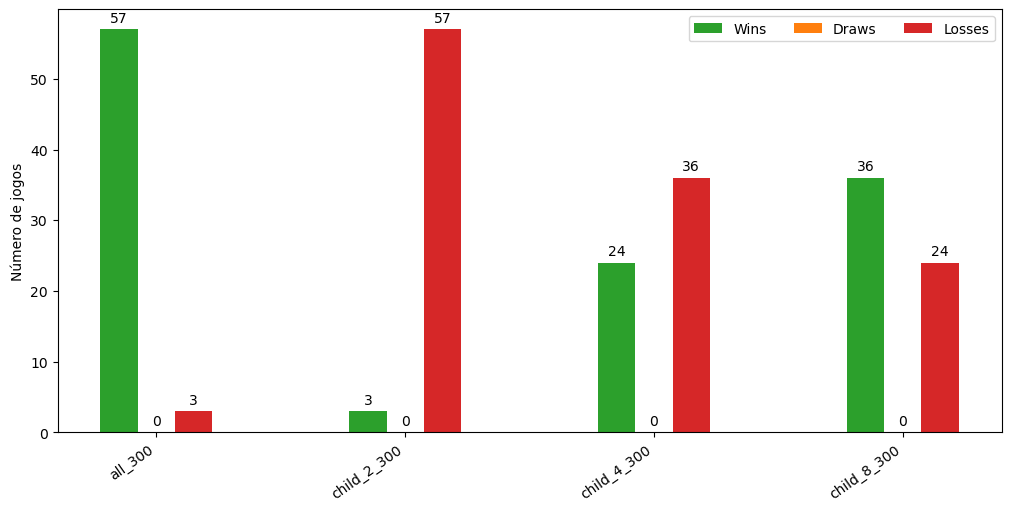

In [ ]:
plot_bars_for_each_var(stats_children, "")

In [ ]:
#vou fazer all vs cada variante, devido ao tempo que demora correr todos contra todos
stats_2 = variants_stats([child_variants_300[0], child_variants_300[1]], n_games=20)  # all vs 2
stats_4 = variants_stats([child_variants_300[0], child_variants_300[2]], n_games=20)  # all vs 4
stats_8 = variants_stats([child_variants_300[0], child_variants_300[3]], n_games=20)  # all vs 8
#n_games=10 =1m55s

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#https://matplotlib.org/stable/gallery/lines_bars_and_markers/barchart.html
def plot_bars_for_each_var(stats, title):
    variants = list(stats.keys())

    measurements = [
        ("Wins",  [stats[v]["wins"]   for v in variants], "#2ca02c"),  # verde
        ("Draws", [stats[v]["draws"]  for v in variants], "#ff7f0e"),  # laranja
        ("Losses",[stats[v]["losses"] for v in variants], "#d62728"),  # vermelho
    ]

    x = np.arange(len(variants))
    width = 0.15
    multiplier = 0

    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

    for label, values, color in measurements:
        offset = width * multiplier
        rects = ax.bar(x + offset, values, width, label=label, color=color)
        ax.bar_label(rects, padding=3)
        multiplier += 1

    ax.set_ylabel("Número de jogos")
    ax.set_title(title)
    ax.set_xticks(x + width, variants, rotation=35, ha="right")
    ax.legend(loc="upper right", ncols=3)

    plt.show()

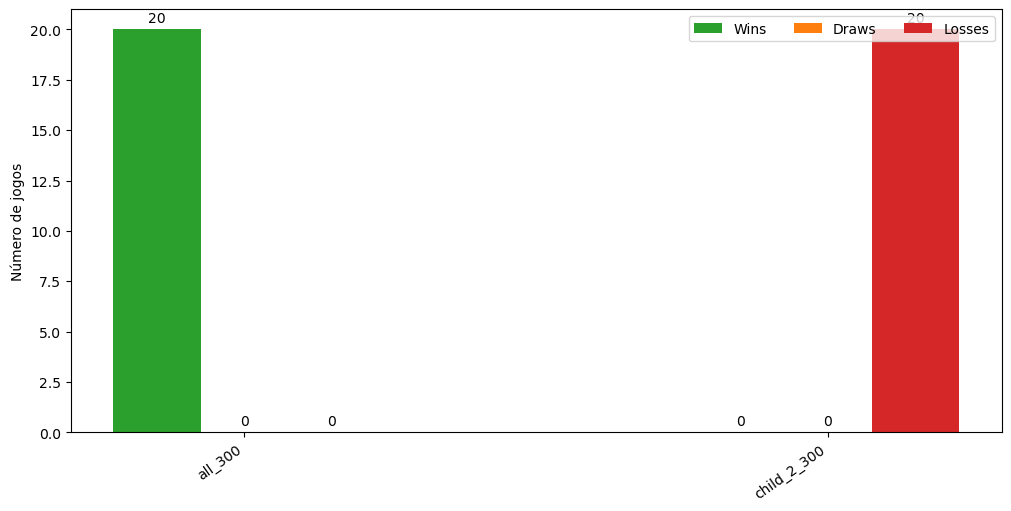

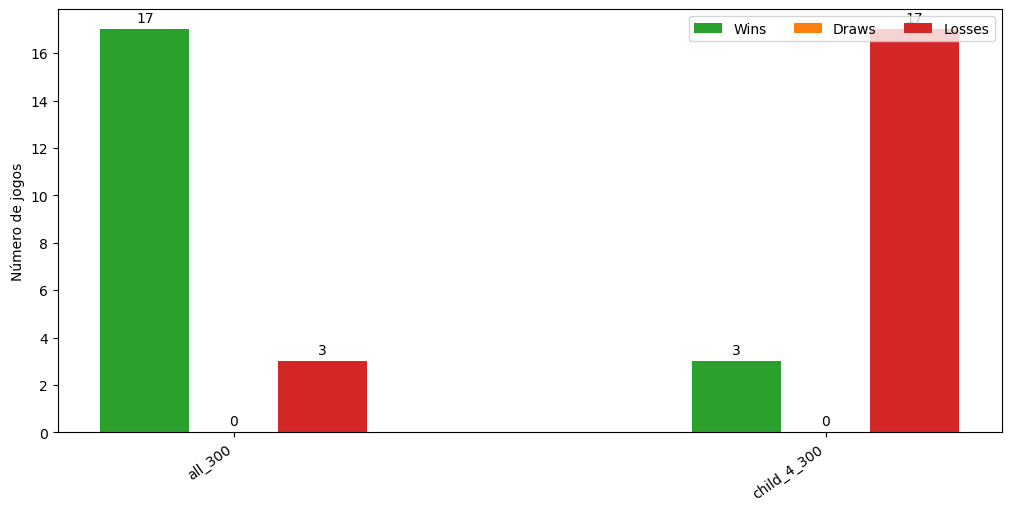

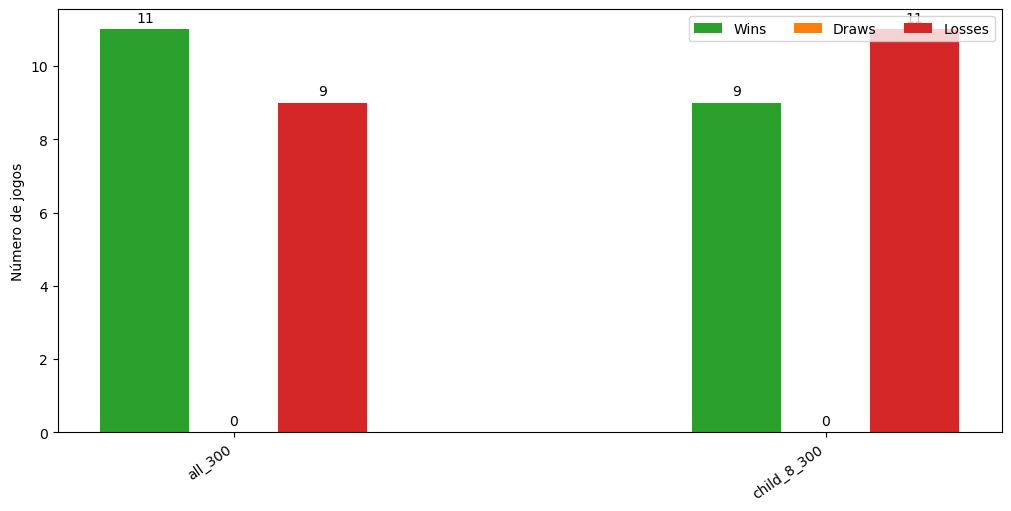

In [7]:
plot_bars_for_each_var(stats_2, "")
plot_bars_for_each_var(stats_4, "")
plot_bars_for_each_var(stats_8, "")

qual sera o efeito das iteracoes na performance do all vs 8 children

In [8]:
iter_variants = [
    ("all_100", MCTS(max_iter=100)),
    ("child_8_100", MCTS(child_limit=8, max_iter=100)),
    ("all_300", MCTS(max_iter=300)),
    ("child_8_300", MCTS(child_limit=8, max_iter=300)),
    ("all_500", MCTS(max_iter=500)),
    ("child_8_500", MCTS(child_limit=8, max_iter=500)),
] 

In [54]:
stats_iter_100 = variants_stats([iter_variants[0], iter_variants[1]], n_games=10)
stats_iter_300 = variants_stats([iter_variants[2], iter_variants[3]], n_games=10)
stats_iter_500 = variants_stats([iter_variants[4], iter_variants[5]], n_games=10)
#n_games=10 = 2m10s

In [8]:
stats_iter_100

{'all_100': {'wins': 9,
  'draws': 0,
  'losses': 11,
  'avg_time_sum': 1.077801831441603,
  'win_rate': 0.45,
  'draw_rate': 0.0,
  'loss_rate': 0.55,
  'avg_time_per_move': 0.05389009157208015},
 'child_8_100': {'wins': 11,
  'draws': 0,
  'losses': 9,
  'avg_time_sum': 1.1141086861118317,
  'win_rate': 0.55,
  'draw_rate': 0.0,
  'loss_rate': 0.45,
  'avg_time_per_move': 0.055705434305591585}}

plot_bars_for_each_var(stats_iter_100, "")
plot_bars_for_each_var(stats_iter_300, "")
plot_bars_for_each_var(stats_iter_500, "")

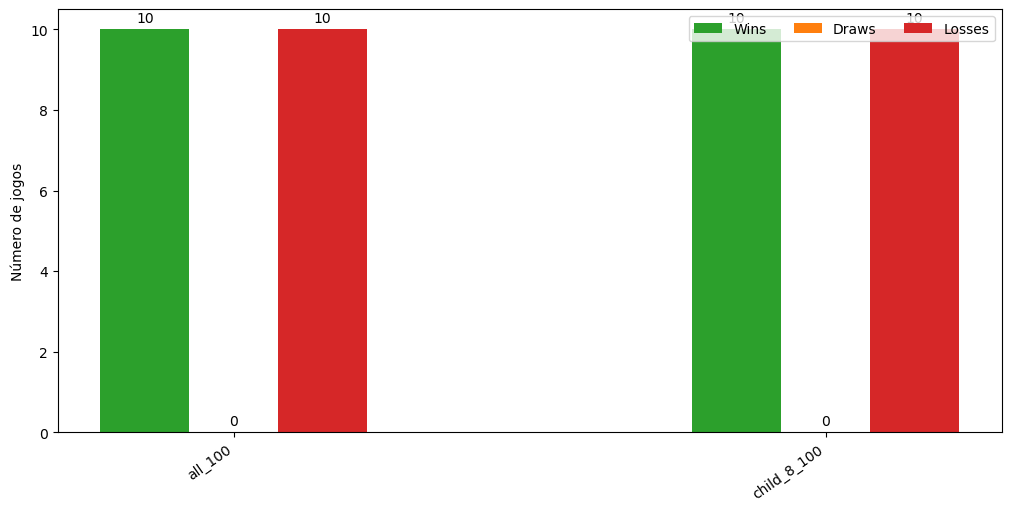

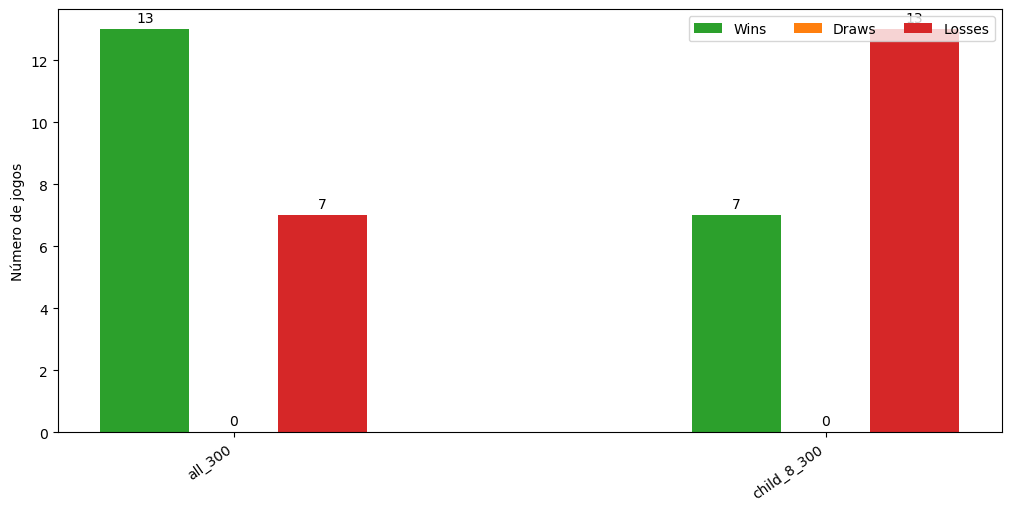

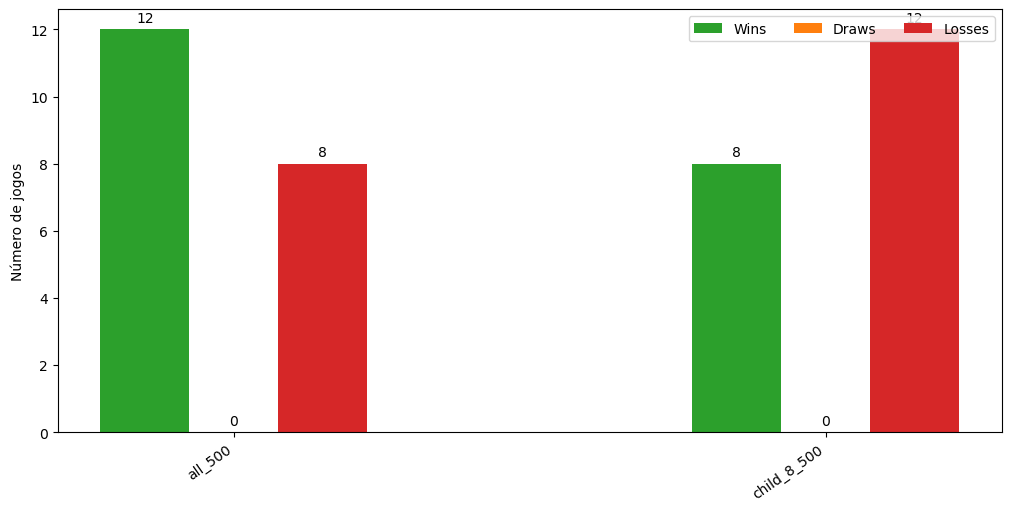

In [10]:
plot_bars_for_each_var(stats_iter_100, "")
plot_bars_for_each_var(stats_iter_300, "")
plot_bars_for_each_var(stats_iter_500, "")

eu estava a espera que com menos iteracoes o que explora 8 children fosse melhor mas a vdd é que sao os 2 maus e como isto tem muito nao determinismo associado e as amostras são pequenas os resultados não nos dizem grande coisa...
será que há alguam vantagem temporal em usar o child_8?
ja agora vê-se a diferença no tempo de todos e pego nos dados anteriores
se calhar move-se isto para antes do all vs o 8

In [21]:
child_limit_time_stats = {
    "all_300": (
        stats_2["all_300"]["avg_time_per_move"]
        + stats_4["all_300"]["avg_time_per_move"]
        + stats_8["all_300"]["avg_time_per_move"]
    ) / 3,
    "child_2_300": stats_2["child_2_300"]["avg_time_per_move"],
    "child_4_300": stats_4["child_4_300"]["avg_time_per_move"],
    "child_8_300": stats_8["child_8_300"]["avg_time_per_move"],
}
all_8_child_limit_time_stats = {
    "all_100":stats_iter_100["all_100"]["avg_time_per_move"],
    "all_300":stats_iter_300["all_300"]["avg_time_per_move"],
    "all_500":stats_iter_500["all_500"]["avg_time_per_move"],
    "child_8_100":stats_iter_100["child_8_100"]["avg_time_per_move"],
    "child_8_300" :stats_iter_300["child_8_300"]["avg_time_per_move"],
    "child_8_500" :stats_iter_500["child_8_500"]["avg_time_per_move"]
}

<BarContainer object of 4 artists>

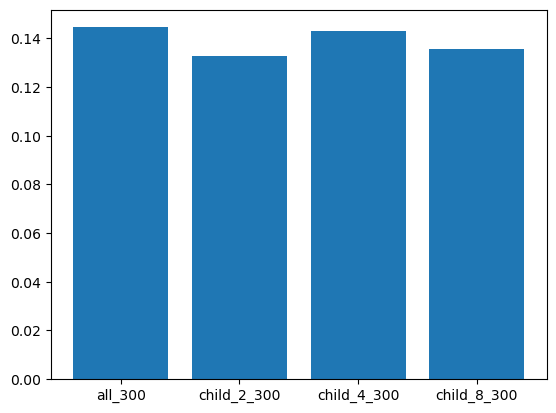

In [22]:
plt.bar(list(child_limit_time_stats.keys()), list(child_limit_time_stats.values()))
#não há diferenca notável

<BarContainer object of 6 artists>

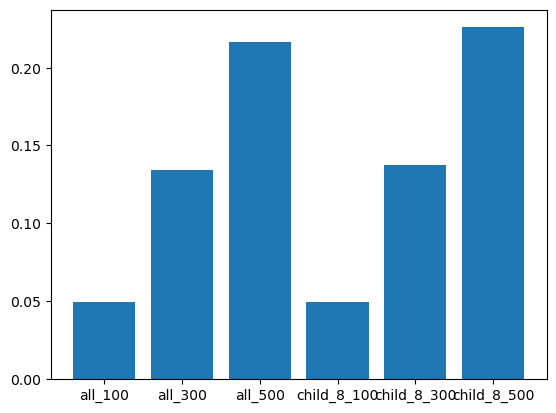

In [23]:
plt.bar(list(all_8_child_limit_time_stats.keys()), list(all_8_child_limit_time_stats.values()))

usar max_iter=100 para comparar todos pq o block é muito lento
pensava que ia usar 200 apesar de ser muito aleatorio mas é uma restricao que temos de assumir, pq o tempo é mesmo demais e pelos resultados que temos conseguimos ver que o win é bom quer para ganhar quer em tempo e a arvore tbm revela algumas vantagens por tanto vou fazer mais iteracoes 
mesmo com 100 iterações e n_games=5 já demora 4m28s 
afinal ao correr novamente nota-se mesmo a variabilidade, o save tree já esta pior e o block ate que calhou bem, mas epa poucas iteracoes e jogos nao da para conlcuir grandes coisas por isso é qeu vamos analisar mais sem o block bla bla bla

In [34]:
#ir buscar os moves possiveis em vez dos estados seria mais rapido principalmente na simualcao do mcts...
heuristic_variants_all = [
    ("base_all_100", MCTS(max_iter=100)),
    ("win_all_100", MCTS(max_iter=100, heuristic_win=True)),
    ("block_all_100", MCTS(max_iter=100, heuristic_block_win=True)),
    ("win_block_all_100", MCTS(max_iter=100, heuristic_win=True, heuristic_block_win=True)),
    ("tree_all_100", MCTS(max_iter=100, save_tree=True)),
    ("full_all_100", MCTS(max_iter=100, heuristic_win=True, heuristic_block_win=True, save_tree=True)),
]

In [35]:
stats_win_all = variants_stats([heuristic_variants_all[0], heuristic_variants_all[1]], n_games=5)
stats_block_all = variants_stats([heuristic_variants_all[0], heuristic_variants_all[2]], n_games=5)
stats_win_block_all = variants_stats([heuristic_variants_all[0], heuristic_variants_all[3]], n_games=5)
stats_tree_all = variants_stats([heuristic_variants_all[0], heuristic_variants_all[4]], n_games=5)
stats_full_all = variants_stats([heuristic_variants_all[0], heuristic_variants_all[5]], n_games=5)

In [36]:
print(stats_win_all["base_all_100"]["avg_time_per_move"])
print(stats_win_all["win_all_100"]["avg_time_per_move"])
print(stats_block_all["block_all_100"]["avg_time_per_move"])
print(stats_win_block_all["win_block_all_100"]["avg_time_per_move"])
print(stats_tree_all["tree_all_100"]["avg_time_per_move"])
print(stats_full_all["full_all_100"]["avg_time_per_move"])

0.05444788802879408
0.02985829479033932
1.5333740385925707
1.0997805491627102
0.05505791074084896
1.1197167590471768


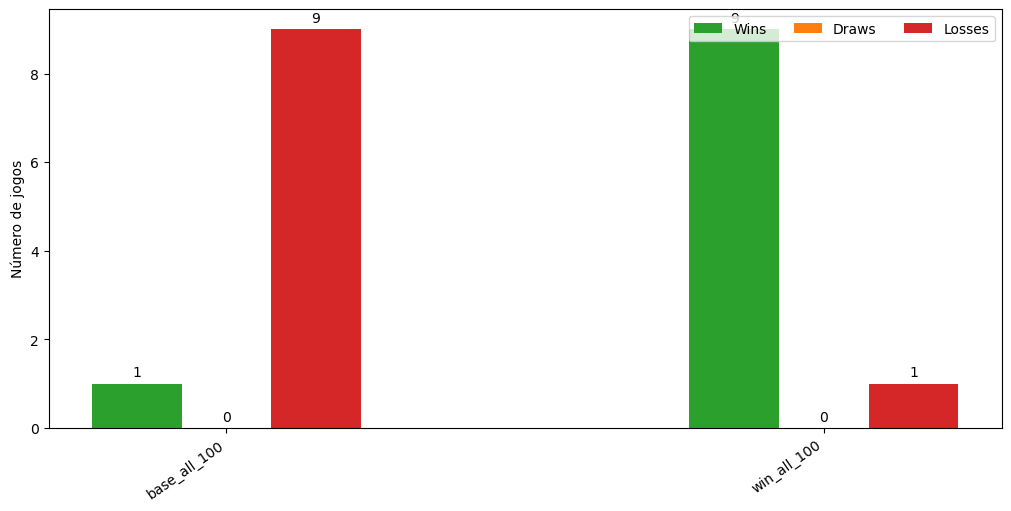

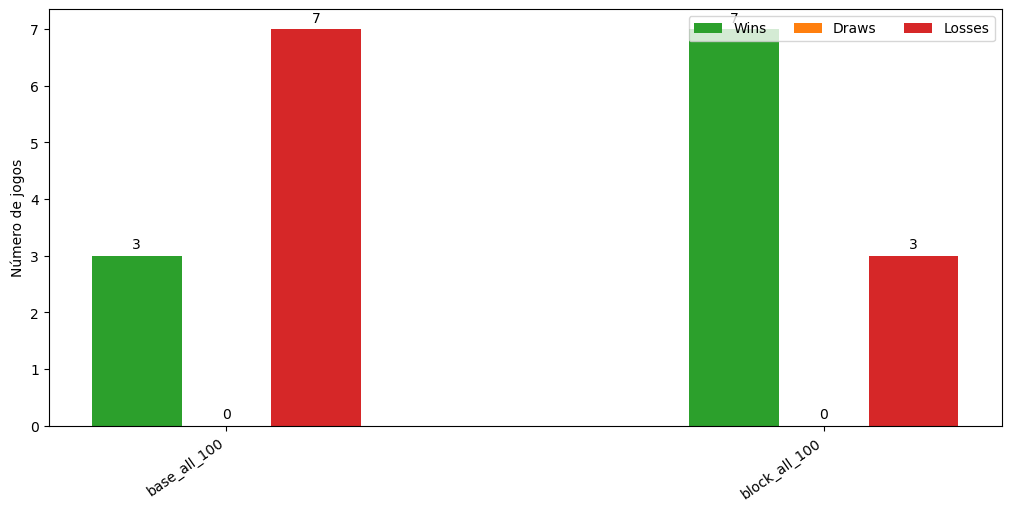

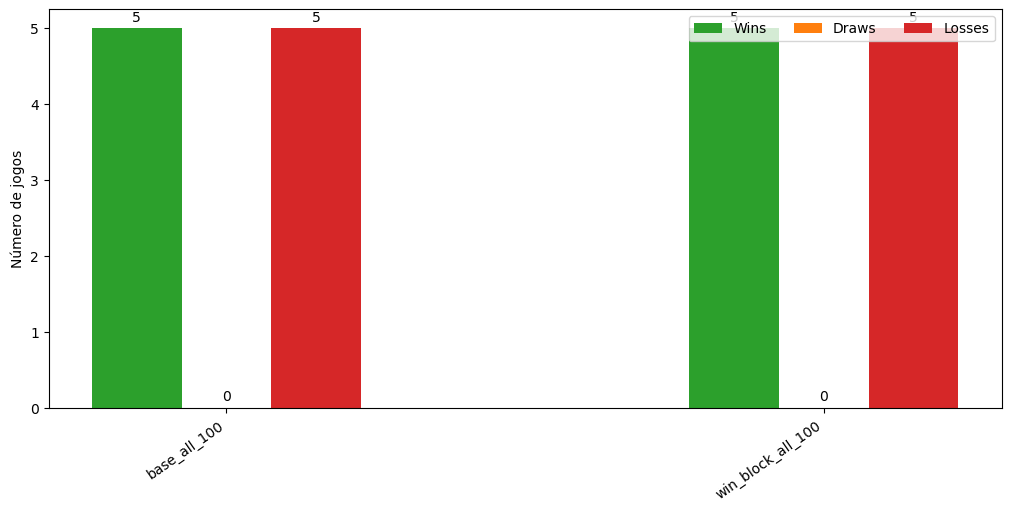

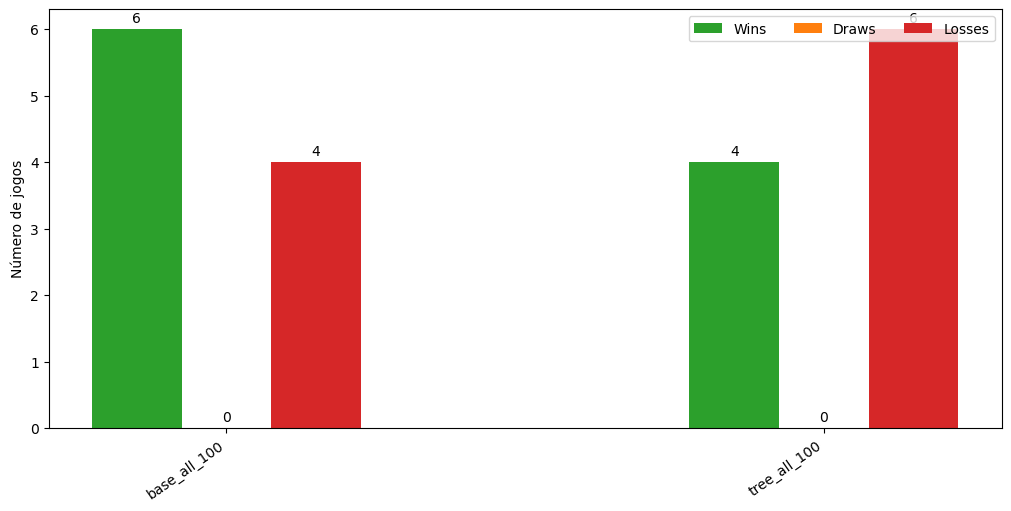

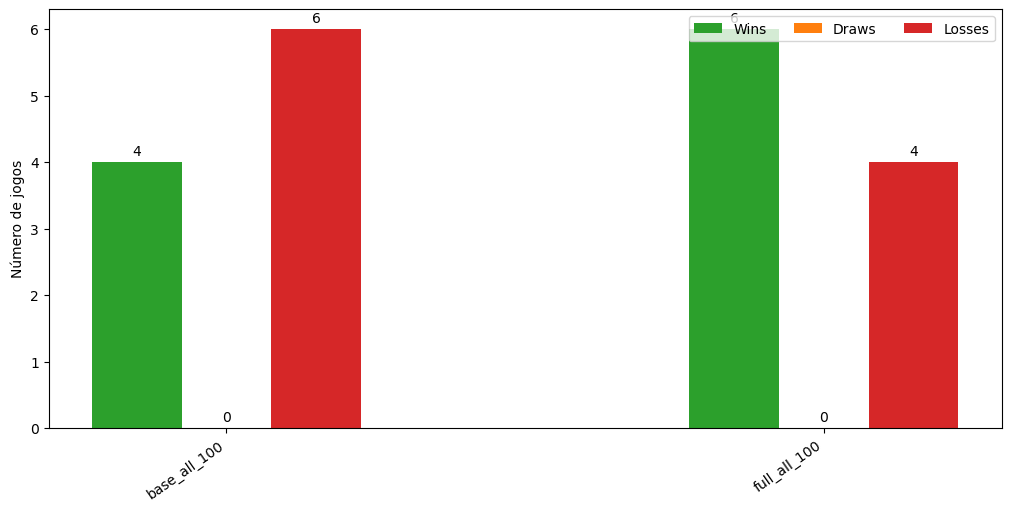

In [37]:
plot_bars_for_each_var(stats_win_all, "")
plot_bars_for_each_var(stats_block_all, "")
plot_bars_for_each_var(stats_win_block_all, "")
plot_bars_for_each_var(stats_tree_all, "")
plot_bars_for_each_var(stats_full_all, "")

nao da para tirar grandes cocnlusoes com 100 simuladoes - muita aleatorieadade
...o que ja escrevi em cima...

In [39]:
heuristic_light_300 = [
    ("base_300", MCTS(max_iter=300)),
    ("win_300", MCTS(max_iter=300, heuristic_win=True)),
    ("tree_300", MCTS(max_iter=300, save_tree=True)),
    ("win_tree_300", MCTS(max_iter=300, heuristic_win=True, save_tree=True)),
]

heuristic_light_500 = [
    ("base_500", MCTS(max_iter=500)),
    ("win_500", MCTS(max_iter=500, heuristic_win=True)),
    ("tree_500", MCTS(max_iter=500, save_tree=True)),
    ("win_tree_500", MCTS(max_iter=500, heuristic_win=True, save_tree=True)),
]

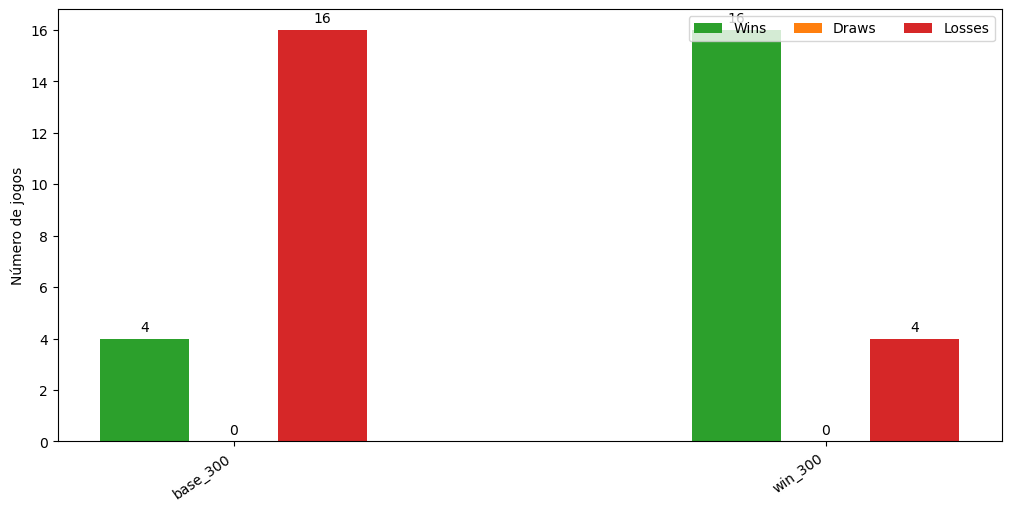

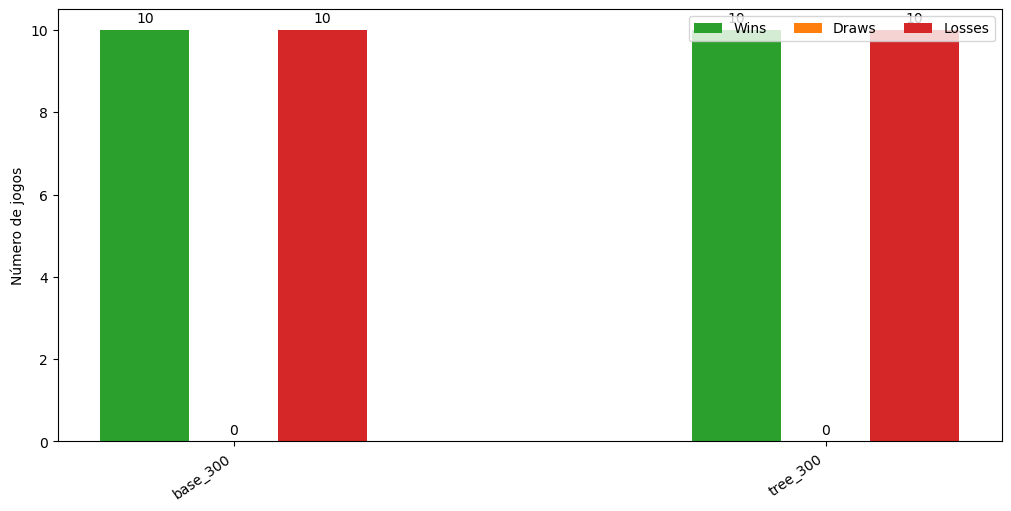

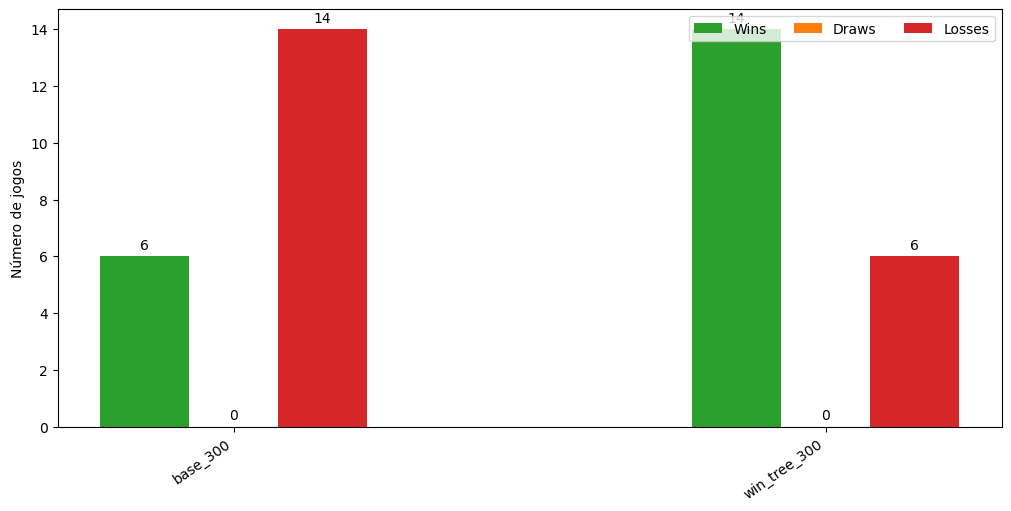

In [ ]:
stats_win_300 = variants_stats([heuristic_light_300[0], heuristic_light_300[1]], n_games=10)
stats_tree_300 = variants_stats([heuristic_light_300[0], heuristic_light_300[2]], n_games=10)
stats_win_tree_300 = variants_stats([heuristic_light_300[0], heuristic_light_300[3]], n_games=10)

plot_bars_for_each_var(stats_win_300, "")
plot_bars_for_each_var(stats_tree_300, "")
plot_bars_for_each_var(stats_win_tree_300, "")

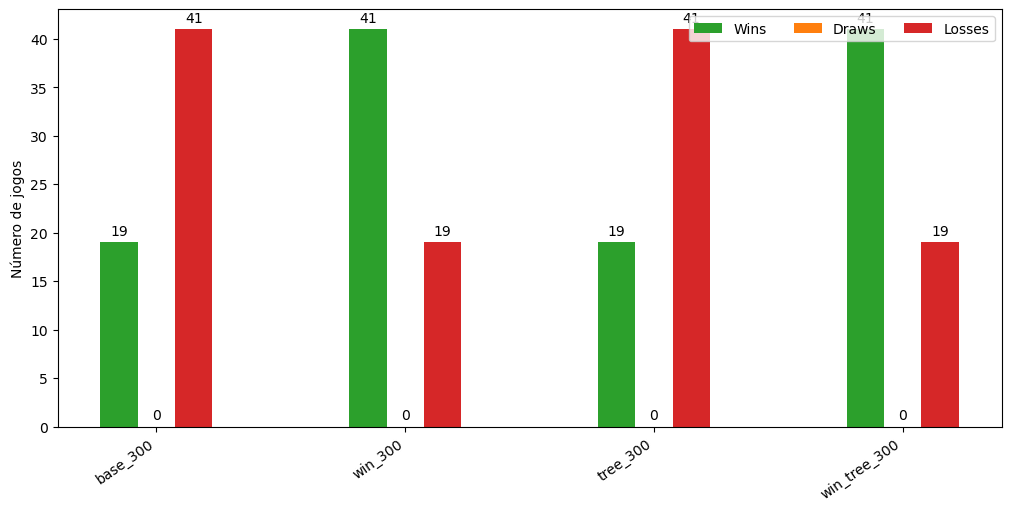

In [ ]:
stats_everything = variants_stats(heuristic_light_300, n_games=10)
plot_bars_for_each_var(stats_everything, "")
#isto é muiot melhor e nem demorou muito tempo o win ajuda a reduzir o tempo não me esquecer disso

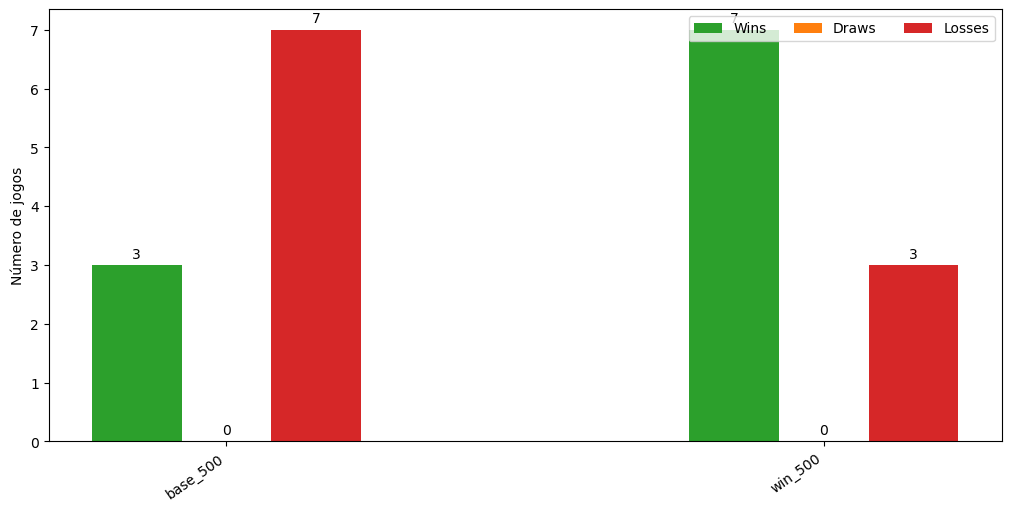

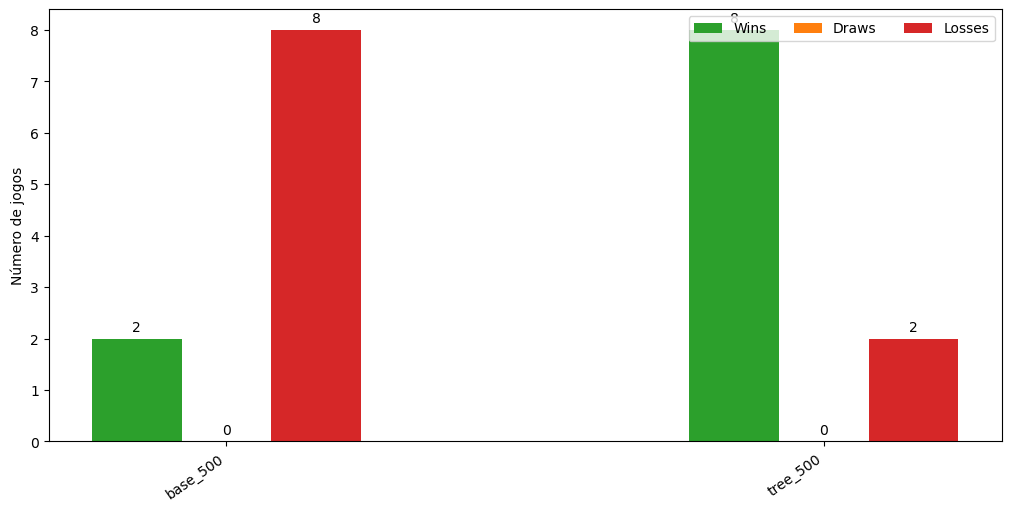

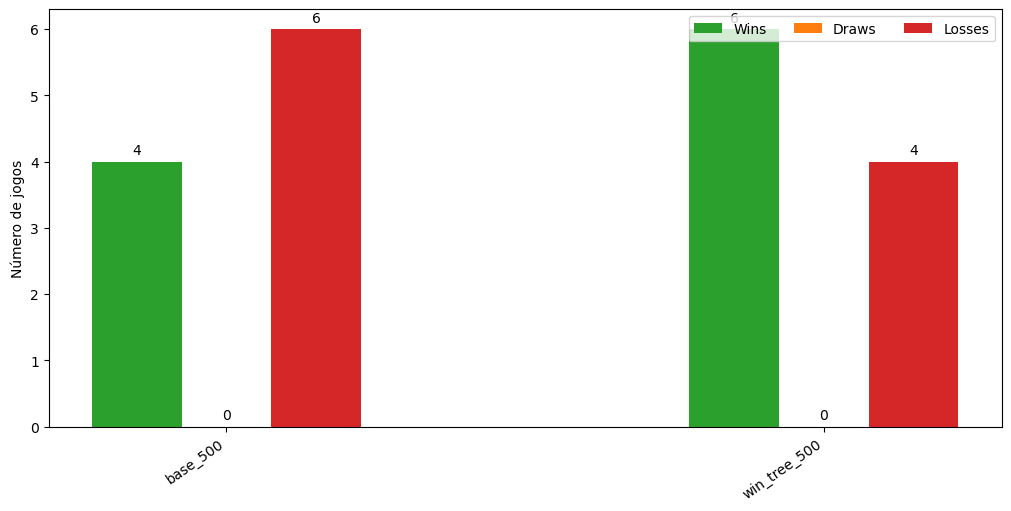

In [ ]:
stats_win_500 = variants_stats([heuristic_light_500[0], heuristic_light_500[1]], n_games=5)
stats_tree_500 = variants_stats([heuristic_light_500[0], heuristic_light_500[2]], n_games=5)
stats_win_tree_500 = variants_stats([heuristic_light_500[0], heuristic_light_500[3]], n_games=5)

plot_bars_for_each_var(stats_win_500, "")
plot_bars_for_each_var(stats_tree_500, "")
plot_bars_for_each_var(stats_win_tree_500, "")
#a tree parece que ta melhor mas pode ser so aleatoriedade eu tbm reduzi o n_games para 5
#mas com mais iters eu esperaria que ela melhorasse

In [ ]:
def plot_win_rate_and_time(results, title):
    names = list(results.keys())
    times = [results[n]["avg_time_per_move"] for n in names]
    wins = [results[n]["win_rate"] for n in names]

    plt.figure(figsize=(8, 5))
    plt.scatter(times, wins)

    for name, x, y in zip(names, times, wins):
        plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))

    plt.xlabel("Tempo médio por jogada (s)")
    plt.ylabel("Win rate")
    plt.title(title)
    plt.grid(True, alpha=0.3) #alpha=transparency
    plt.show()

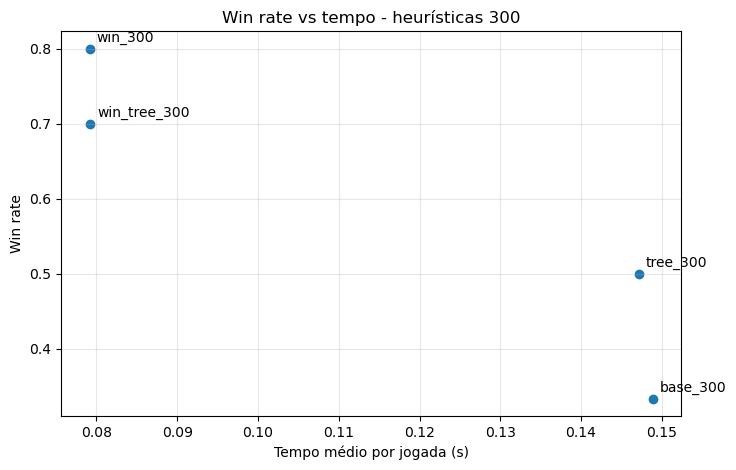

In [ ]:
#ter em conta que a base jogou contra todos
#estou a questionar as minhas escolhas de vida e se calhar é melhor deixar testar todso contra todos
#como ja nao se usa o block pode ser que seja viável
#se calhar mais vale so deixar durante a noite inteira e ter bons resultados , que se lixe a minha deifnicao de viavel
base_300_tradeoff = {
    "win_rate": (
        stats_win_300["base_300"]["win_rate"]
        + stats_tree_300["base_300"]["win_rate"]
        + stats_win_tree_300["base_300"]["win_rate"]
    ) / 3,
    "avg_time_per_move": (
        stats_win_300["base_300"]["avg_time_per_move"]
        + stats_tree_300["base_300"]["avg_time_per_move"]
        + stats_win_tree_300["base_300"]["avg_time_per_move"]
    ) / 3,
}

heuristic_tradeoff_300 = {
    "base_300": base_300_tradeoff,
    "win_300": stats_win_300["win_300"],
    "tree_300": stats_tree_300["tree_300"],
    "win_tree_300": stats_win_tree_300["win_tree_300"],
}
plot_win_rate_and_time(heuristic_tradeoff_300, "Win rate vs tempo - heurísticas 300")

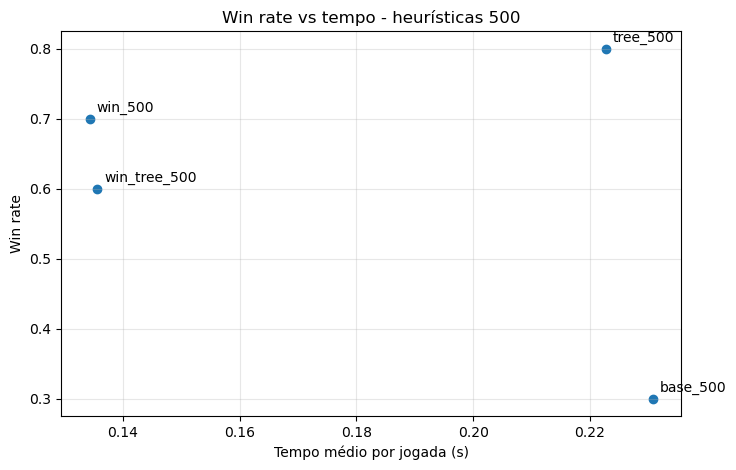

In [49]:
base_500_tradeoff = {
    "win_rate": (
        stats_win_500["base_500"]["win_rate"]
        + stats_tree_500["base_500"]["win_rate"]
        + stats_win_tree_500["base_500"]["win_rate"]
    ) / 3,
    "avg_time_per_move": (
        stats_win_500["base_500"]["avg_time_per_move"]
        + stats_tree_500["base_500"]["avg_time_per_move"]
        + stats_win_tree_500["base_500"]["avg_time_per_move"]
    ) / 3,
}

heuristic_tradeoff_500 = {
    "base_500": base_500_tradeoff,
    "win_500": stats_win_500["win_500"],
    "tree_500": stats_tree_500["tree_500"],
    "win_tree_500": stats_win_tree_500["win_tree_500"],
}

plot_win_rate_and_time(heuristic_tradeoff_500, "Win rate vs tempo - heurísticas 500")

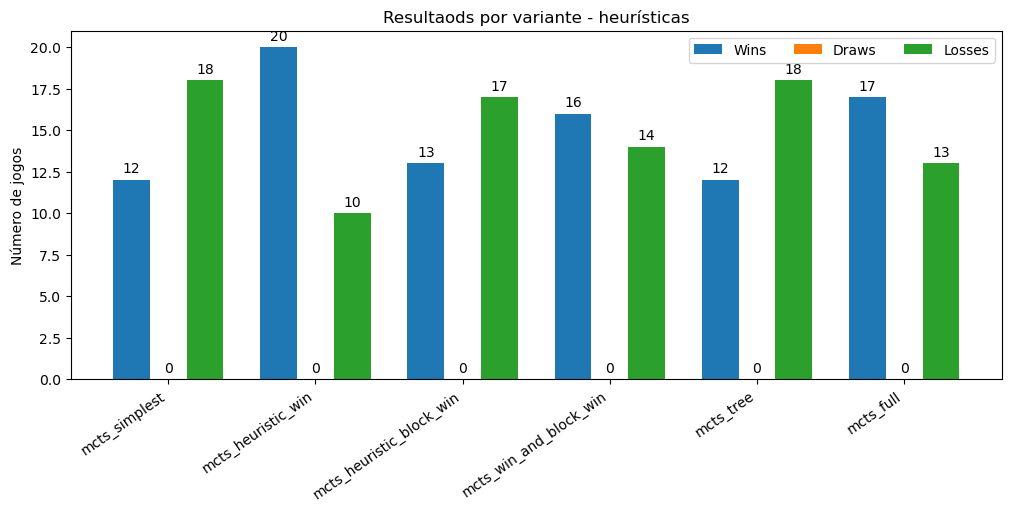

In [ ]:
#resquícios de algo que teve a correr durante 220 mins
plot_bars_for_each_var(heuristic_stats, "Resultaods por variante - heurísticas")